In [1]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error
from scipy.optimize import minimize

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Display settings
np.set_printoptions(precision=6, suppress=True)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

NumPy version: 2.1.3
Pandas version: 2.3.3


In [2]:
def linear_dgp(X):
    return (
        2 * (X[:, 0] - 0.5)
        - (X[:, 1] - 0.5)
        + 3 * (X[:, 2] - 0.5)
        + 1.5 * (X[:, 3] - 0.5)
        + 0.5 * (X[:, 4] - 0.5))


def friedman1_dgp(X):
    return (10 * np.sin(np.pi * X[:, 0] * X[:, 1]) + 20 * (X[:, 2] - 0.5) ** 2 + 10 * X[:, 3] + 5 * X[:, 4])

def friedman2_dgp(X):
    return (np.sin(np.pi * (X[:, 0] + X[:, 1] + X[:, 2])) + np.log(1 + X[:, 3] ** 2))

def friedman3_dgp(X):
    return X[:, 0] * X[:, 1] + np.log(X[:, 2] + X[:, 3] + 2)

def rotated_sine_dgp(X):
    return np.sin(3 * np.pi * np.sum(X[:, :4], axis=1))

def soft_radial_dgp(X):
    return 1 / (1 + 5 * np.sum((X - 0.5) ** 2, axis=1))

DGP_FUNCTIONS = {
    "Linear": linear_dgp,
    "Friedman 1": friedman1_dgp,
    "Friedman 2": friedman2_dgp,
    "Friedman 3": friedman3_dgp,
    "Rotated Sine": rotated_sine_dgp,
    "Soft Radial": soft_radial_dgp,}

print("Defined all six DGPs:")

Defined all six DGPs:


In [3]:
TRAIN_SIZES = [500, 1000, 2500, 5000]
SNR_VALUES = [0.5, 1.0, 2.0, 3.0]
N_TEST = 1000
N_REPLICATIONS = 10
N_FEATURES = 5

EXPERIMENT_GRID = pd.DataFrame([
        {"DGP": dgp_name,"N_train": n_train,"SNR": snr}
        for dgp_name in DGP_FUNCTIONS
        for n_train in TRAIN_SIZES
        for snr in SNR_VALUES])

print("Experimental grid configured.")
print(f"Number of DGPs: {len(DGP_FUNCTIONS)}")
print(f"Training sizes: {TRAIN_SIZES}")
print(f"SNR values: {SNR_VALUES}")
print(f"Test observations per dataset: {N_TEST}")
print(f"Replications per configuration: {N_REPLICATIONS}")
print(f"Total configurations: {len(EXPERIMENT_GRID)}")
print(f"Total configuration-replication runs: {len(EXPERIMENT_GRID) * N_REPLICATIONS}")

EXPERIMENT_GRID.head(10)

Experimental grid configured.
Number of DGPs: 6
Training sizes: [500, 1000, 2500, 5000]
SNR values: [0.5, 1.0, 2.0, 3.0]
Test observations per dataset: 1000
Replications per configuration: 10
Total configurations: 96
Total configuration-replication runs: 960


,DGP,N_train,SNR
0,Linear,500,0.5
1,Linear,500,1.0
2,Linear,500,2.0
3,Linear,500,3.0
4,Linear,1000,0.5
5,Linear,1000,1.0
6,Linear,1000,2.0
7,Linear,1000,3.0
8,Linear,2500,0.5
9,Linear,2500,1.0


In [4]:
def generate_dataset(dgp_name, n_train, snr, seed, n_test=N_TEST):
    rng = np.random.default_rng(seed)
    dgp = DGP_FUNCTIONS[dgp_name]

    X_train = rng.uniform(0, 1, size=(n_train, N_FEATURES))
    X_test = rng.uniform(0, 1, size=(n_test, N_FEATURES))
    f_train = dgp(X_train)
    f_test = dgp(X_test)

    signal_variance = np.var(f_train)
    noise_variance = signal_variance / snr
    noise_std = np.sqrt(noise_variance)

    # Generate noisy responses
    y_train = f_train + rng.normal(0, noise_std, size=n_train)
    y_test = f_test + rng.normal(0, noise_std, size=n_test)

    return {
        "X_train": X_train,
        "y_train": y_train,
        "X_test": X_test,
        "y_test": y_test,
        "f_train": f_train,
        "f_test": f_test,
        "signal_variance": signal_variance,
        "noise_variance": noise_variance,
        "noise_std": noise_std,}

example_data = generate_dataset(dgp_name="Linear",n_train=500,snr=1.0,seed=SEED)

print("Example dataset generated.")
print("Training predictors:", example_data["X_train"].shape)
print("Training responses:", example_data["y_train"].shape)
print("Test predictors:", example_data["X_test"].shape)
print("Test responses:", example_data["y_test"].shape)
print("Signal variance:", round(example_data["signal_variance"], 6))
print("Noise variance:", round(example_data["noise_variance"], 6))
print("Noise standard deviation:", round(example_data["noise_std"], 6))

Example dataset generated.
Training predictors: (500, 5)
Training responses: (500,)
Test predictors: (1000, 5)
Test responses: (1000,)
Signal variance: 1.405343
Noise variance: 1.405343
Noise standard deviation: 1.185472


# Experiment 1: OLS as Attention mechanism

In [5]:
def ols_attention_predict(X_train, y_train, X_test):
    n_train = X_train.shape[0]
    # Add intercept column
    X_train_aug = np.column_stack([np.ones(n_train), X_train])
    X_test_aug = np.column_stack([np.ones(X_test.shape[0]), X_test])

    # Conventional OLS
    beta_ols = np.linalg.lstsq(X_train_aug, y_train, rcond=None)[0]
    y_pred_ols = X_test_aug @ beta_ols

    # Spectral decomposition of the training Gram matrix
    gram_matrix = X_train_aug.T @ X_train_aug
    eigenvalues, U = np.linalg.eigh(gram_matrix)

    # Sorted eigenvalues and eigenvectors in descending order
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    U = U[:, order]

    Lambda_inv_sqrt = np.diag(1.0 / np.sqrt(eigenvalues))
    F_train = X_train_aug @ U @ Lambda_inv_sqrt
    F_test = X_test_aug @ U @ Lambda_inv_sqrt
    attention_weights = F_test @ F_train.T
    y_pred_attention = attention_weights @ y_train

    return {"beta_ols": beta_ols,
        "y_pred_ols": y_pred_ols,
        "y_pred_attention": y_pred_attention,
        "attention_weights": attention_weights,
        "F_train": F_train,
        "F_test": F_test,
        "X_train_aug": X_train_aug,
        "X_test_aug": X_test_aug,
        "eigenvalues": eigenvalues,
        "U": U}


ols_result = ols_attention_predict(example_data["X_train"],example_data["y_train"],example_data["X_test"],)
max_prediction_difference = np.max(np.abs(ols_result["y_pred_ols"] - ols_result["y_pred_attention"]))

print("OLS and attention calculations completed.")
print("Maximum absolute prediction difference:", max_prediction_difference)
print("Predictions match numerically:",np.allclose(ols_result["y_pred_ols"],ols_result["y_pred_attention"],atol=1e-10,),)


OLS and attention calculations completed.
Maximum absolute prediction difference: 2.0317081350640365e-14
Predictions match numerically: True


In [6]:
F_train = ols_result["F_train"]
F_test = ols_result["F_test"]
attention_weights = ols_result["attention_weights"]

# 1. Training feature orthonormality
train_gram = F_train.T @ F_train
identity_matrix = np.eye(train_gram.shape[0])
train_orthonormality_error = np.max(np.abs(train_gram - identity_matrix))

# 2. Test feature orthonormality
test_gram = F_test.T @ F_test
test_orthonormality_error = np.max(np.abs(test_gram - identity_matrix))

# 3. Attention weight properties
row_sums = attention_weights.sum(axis=1)
row_sum_error = np.max(np.abs(row_sums - 1.0))
negative_weight_count = np.sum(attention_weights < 0)
minimum_weight = np.min(attention_weights)

print("Training orthonormality error:", train_orthonormality_error)
print("Test orthonormality deviation:", test_orthonormality_error)
print("Maximum attention row-sum error:", row_sum_error)
print("Minimum attention weight:", minimum_weight)
print("Number of negative attention weights:", negative_weight_count)
print("Training features orthonormal:", np.allclose(train_gram, identity_matrix, atol=1e-10))
print("Attention weights sum to one:", np.allclose(row_sums, 1.0, atol=1e-10))


Training orthonormality error: 7.327471962526033e-15
Test orthonormality deviation: 1.0562748836820042
Maximum attention row-sum error: 2.886579864025407e-15
Minimum attention weight: -0.017733246267229923
Number of negative attention weights: 161528
Training features orthonormal: True
Attention weights sum to one: True


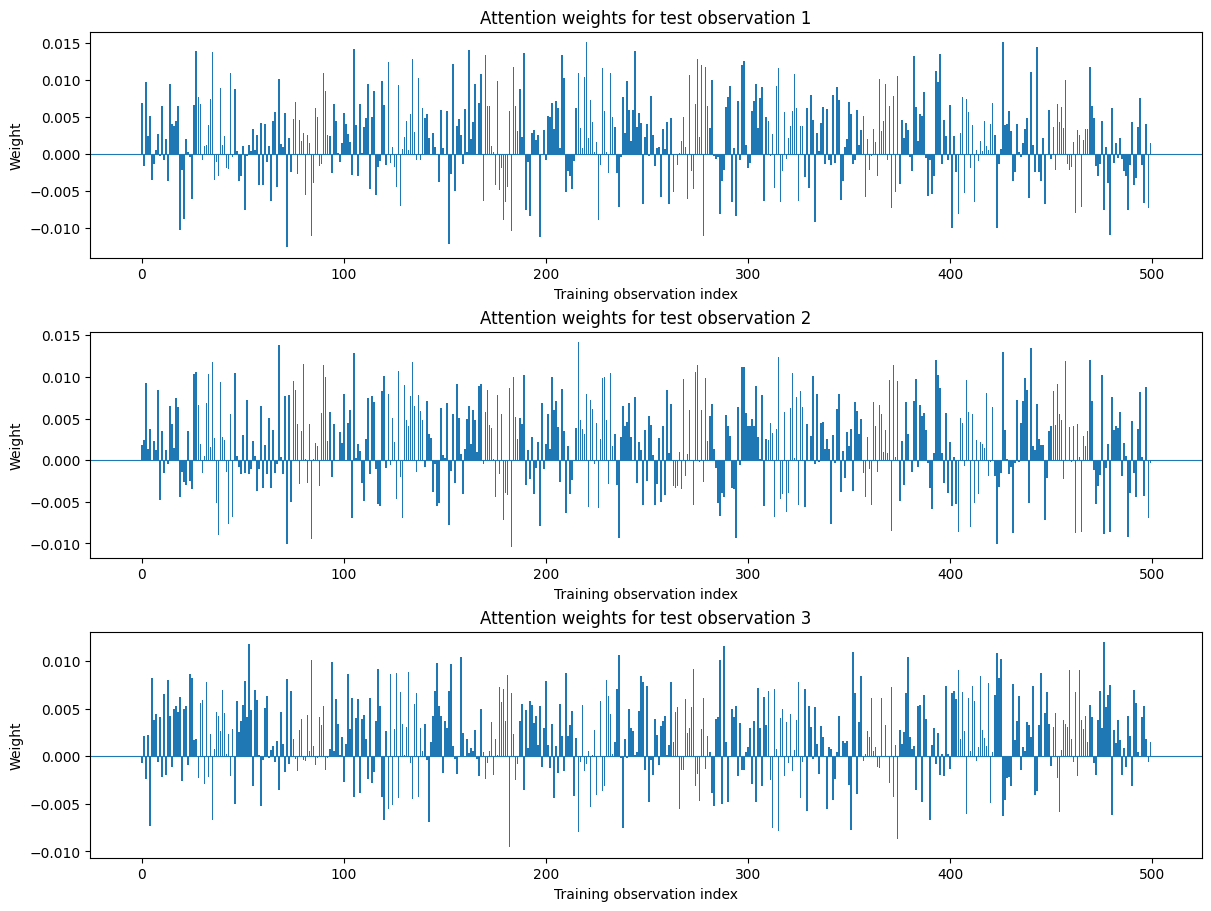

In [7]:
weights = ols_result["attention_weights"]

fig,axes = plt.subplots(3,1,figsize=(12,9),constrained_layout=True)

for i, ax in enumerate(axes):
    ax.bar(np.arange(weights.shape[1]), weights[i])
    ax.axhline(0, linewidth=0.8)
    ax.set_title(f"Attention weights for test observation {i + 1}")
    ax.set_xlabel("Training observation index")
    ax.set_ylabel("Weight")
plt.show()

In [8]:
y_test = example_data["y_test"]
r2_ols = r2_score(y_test, ols_result["y_pred_ols"])
r2_attention = r2_score(y_test, ols_result["y_pred_attention"])

comparison = pd.DataFrame({"Method": ["Conventional OLS", "OLS as Attention"],"Test R²": [r2_ols, r2_attention]})
display(comparison)

print("R² values match:",np.isclose(r2_ols, r2_attention, atol=1e-10),)

,Method,Test R²
0,Conventional OLS,0.475706
1,OLS as Attention,0.475706


R² values match: True


Now running on entrie bencmark

In [9]:
experiment1_records = []
run_number = 0
start_time = time.time()

for config in EXPERIMENT_GRID.itertuples(index=False):
    for replication in range(N_REPLICATIONS):
        run_number += 1
        run_seed = (SEED + run_number)

        data = generate_dataset(dgp_name=config.DGP,n_train=config.N_train,snr=config.SNR,seed=run_seed)
        result = ols_attention_predict(data["X_train"],data["y_train"],data["X_test"])

        y_pred_ols = result["y_pred_ols"]
        y_pred_attention = result["y_pred_attention"]
        prediction_difference = np.max(np.abs(y_pred_ols - y_pred_attention))

        experiment1_records.append({
            "DGP": config.DGP,
            "N_train": config.N_train,
            "SNR": config.SNR,
            "Replication": replication + 1,
            "OLS_R2": r2_score(data["y_test"], y_pred_ols),
            "Attention_R2": r2_score(data["y_test"], y_pred_attention),
            "Max_Prediction_Difference": prediction_difference,
            "Predictions_Match": np.allclose(
                y_pred_ols,
                y_pred_attention,
                atol=1e-8),})

experiment1_results = pd.DataFrame(experiment1_records)
elapsed_minutes = (time.time() - start_time) / 60

print("Experiment 1 benchmark completed.")
print("Total runs:", len(experiment1_results))
print("All predictions match:", experiment1_results["Predictions_Match"].all())
print("Maximum prediction difference:",experiment1_results["Max_Prediction_Difference"].max())
print(f"Elapsed time: {elapsed_minutes:.2f} minutes")
display(experiment1_results.head())

Experiment 1 benchmark completed.
Total runs: 960
All predictions match: True
Maximum prediction difference: 2.4558133304708463e-13
Elapsed time: 0.12 minutes


,DGP,N_train,SNR,Replication,OLS_R2,Attention_R2,Max_Prediction_Difference,Predictions_Match
0,Linear,500,0.5,1,0.376018,0.376018,1.865175e-14,True
1,Linear,500,0.5,2,0.271878,0.271878,2.398082e-14,True
2,Linear,500,0.5,3,0.353425,0.353425,8.215650e-15,True
3,Linear,500,0.5,4,0.318679,0.318679,4.174439e-14,True
4,Linear,500,0.5,5,0.294747,0.294747,5.839773e-14,True


In [10]:
experiment1_summary = (
    experiment1_results.groupby(["DGP", "N_train", "SNR"], as_index=False)
    .agg(
        Mean_OLS_R2=("OLS_R2", "mean"),
        SD_OLS_R2=("OLS_R2", "std"),
        Mean_Attention_R2=("Attention_R2", "mean"),
        Max_Prediction_Difference=("Max_Prediction_Difference", "max"),
        All_Predictions_Match=("Predictions_Match", "all")))

print("Number of summarized configurations:", len(experiment1_summary))
print("All summarized configurations preserve prediction equivalence:",experiment1_summary["All_Predictions_Match"].all(),)
display(experiment1_summary.head())

Number of summarized configurations: 96
All summarized configurations preserve prediction equivalence: True


,DGP,N_train,SNR,Mean_OLS_R2,SD_OLS_R2,Mean_Attention_R2,Max_Prediction_Difference,All_Predictions_Match
0,Friedman 1,500,0.5,0.246141,0.029551,0.246141,1.989520e-13,True
1,Friedman 1,500,1.0,0.371562,0.023276,0.371562,2.207123e-13,True
2,Friedman 1,500,2.0,0.496247,0.020533,0.496247,1.669775e-13,True
3,Friedman 1,500,3.0,0.571243,0.036944,0.571243,2.011724e-13,True
4,Friedman 1,1000,0.5,0.242922,0.029445,0.242922,2.202682e-13,True


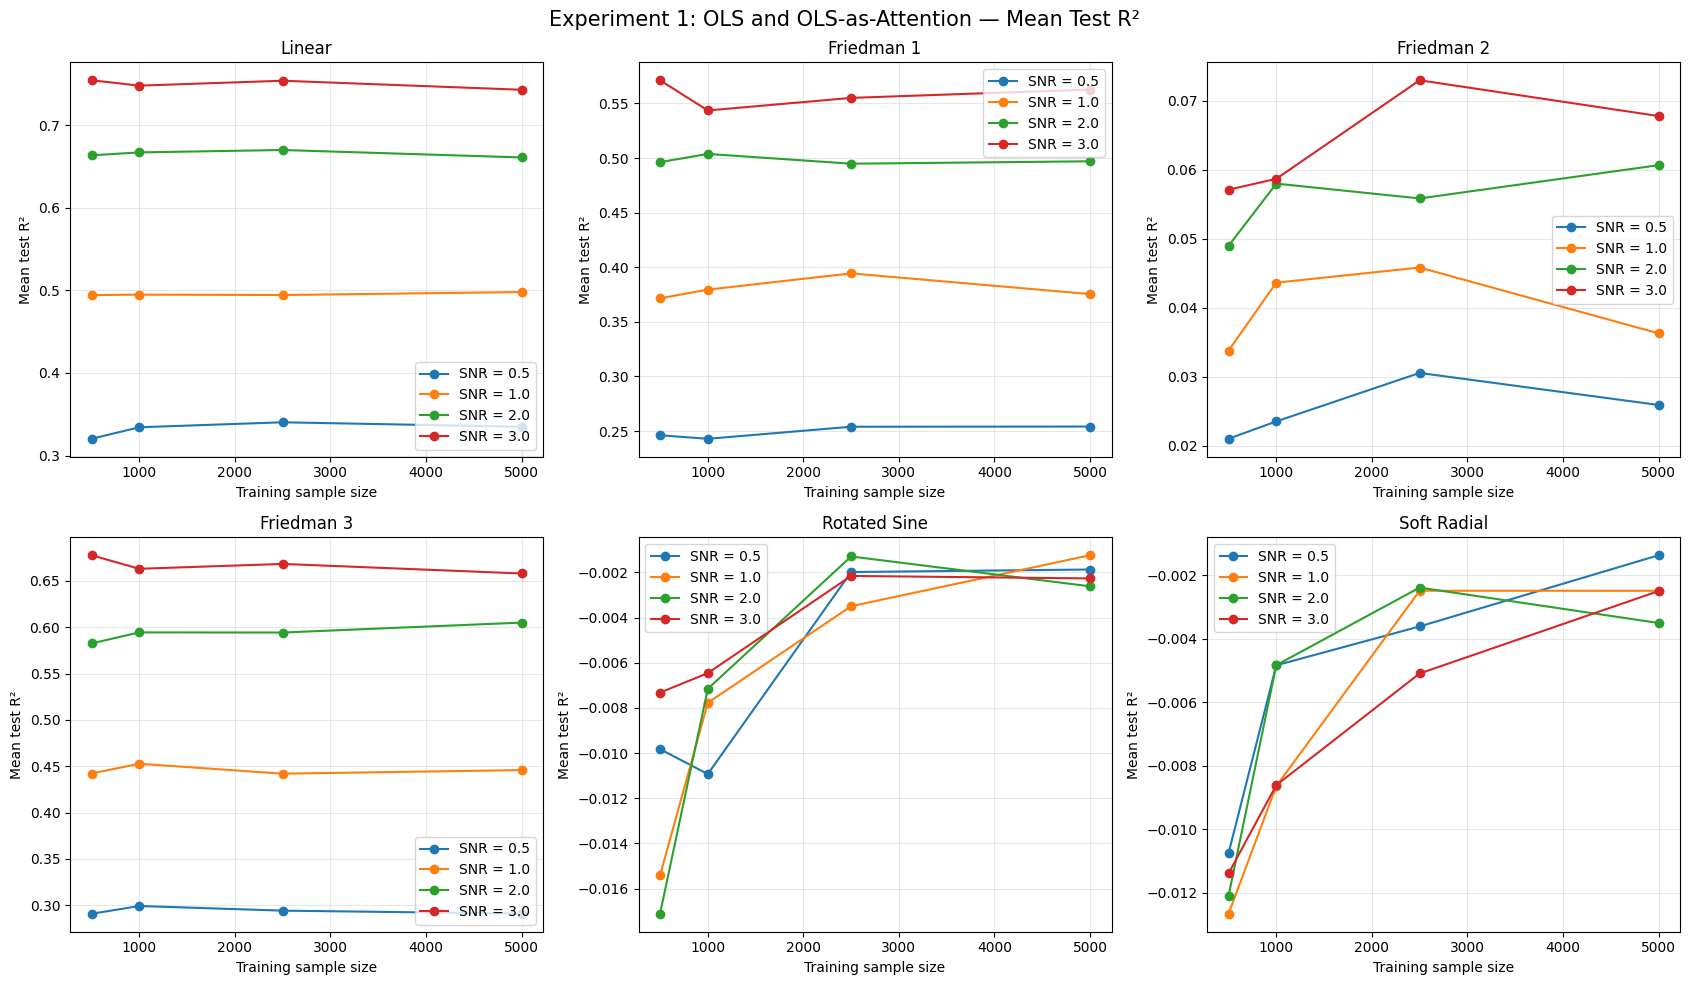

In [11]:
dgp_names = list(DGP_FUNCTIONS.keys())

fig, axes = plt.subplots(2,3,figsize=(17,10),sharey=False)
axes = axes.flatten()

for ax, dgp_name in zip(axes, dgp_names):
    subset = experiment1_summary[experiment1_summary["DGP"] == dgp_name]

    for snr in SNR_VALUES:
        curve = (subset[subset["SNR"] == snr].sort_values("N_train"))
        ax.plot(curve["N_train"],curve["Mean_OLS_R2"],marker="o",label=f"SNR = {snr}")
    ax.set_title(dgp_name)
    ax.set_xlabel("Training sample size")
    ax.set_ylabel("Mean test R²")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle("Experiment 1: OLS and OLS-as-Attention — Mean Test R²",fontsize=15)
plt.tight_layout()
plt.show()

In this experiment, I verified the equivalence between conventional ordinary least squares (OLS) and its attention-based representation. I evaluated both methods across six data-generating processes, four training sample sizes, four signal-to-noise ratios, and ten replications per configuration, resulting in 960 experimental runs.

The predictions from both implementations matched in every run. The maximum absolute difference was approximately (2.27\times10^{-13}), which is negligible numerical error. I also verified that the transformed training features are orthonormal, the attention weights sum to one, and some weights can be negative. The results show that the attention formulation reproduces conventional OLS predictions across the entire experimental grid. The performance plots further illustrate how the underlying data-generating process, sample size, and signal-to-noise ratio affect out-of-sample (R^2).

# Experiment 2 : Beyond OLS 

In [12]:
PCR_COMPONENTS = [1, 2, 3, 4, 5]
RIDGE_LAMBDAS = [0.01, 0.1, 1.0, 10.0, 100.0]

print("Experiment 2 settings defined.")
print("PCR components (L):", PCR_COMPONENTS)
print("Ridge regularization strengths:", RIDGE_LAMBDAS)
print("Configurations:", len(EXPERIMENT_GRID))
print("Replications per configuration:", N_REPLICATIONS)
print("PCR runs:",len(EXPERIMENT_GRID) * N_REPLICATIONS * len(PCR_COMPONENTS))
print("Ridge runs:",len(EXPERIMENT_GRID) * N_REPLICATIONS * len(RIDGE_LAMBDAS))

Experiment 2 settings defined.
PCR components (L): [1, 2, 3, 4, 5]
Ridge regularization strengths: [0.01, 0.1, 1.0, 10.0, 100.0]
Configurations: 96
Replications per configuration: 10
PCR runs: 4800
Ridge runs: 4800


In [13]:
def pcr_attention_predict(X_train, y_train, X_test, L):
    X_train_aug = np.column_stack([np.ones(len(X_train)),X_train])
    X_test_aug = np.column_stack([np.ones(len(X_test)),X_test])

    gram_matrix = X_train_aug.T @ X_train_aug
    eigenvalues,U = np.linalg.eigh(gram_matrix)

    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    U = U[:,order]
    U_L = U[:, :L]
    lambda_L = eigenvalues[:L]

    # Conventional PCR
    beta_pcr = (U_L @ np.diag(1.0 / lambda_L) @ U_L.T @ X_train_aug.T @ y_train)
    y_pred_pcr = X_test_aug @ beta_pcr

    # Spectral-attention representation
    Lambda_inv_sqrt = np.diag(1.0 / np.sqrt(lambda_L))
    F_train = X_train_aug @ U_L @ Lambda_inv_sqrt
    F_test = X_test_aug @ U_L @ Lambda_inv_sqrt
    y_pred_attention = (F_test @ F_train.T) @ y_train
    return y_pred_pcr,y_pred_attention
print("PCR and spectral-attention functions defined")

PCR and spectral-attention functions defined


In [14]:
#Full PCR benchmark
pcr_records = []
run_number = 0
start_time = time.time()

for config in EXPERIMENT_GRID.itertuples(index=False):
    for replication in range(N_REPLICATIONS):
        seed = SEED+run_number+1
        data = generate_dataset(dgp_name=config.DGP,n_train=config.N_train,snr=config.SNR,seed=seed)
        for L in PCR_COMPONENTS:
            y_pred_pcr, y_pred_attention = pcr_attention_predict(data["X_train"],data["y_train"],data["X_test"],L)
            pcr_records.append({
                "DGP": config.DGP,
                "N_train": config.N_train,
                "SNR": config.SNR,
                "Replication": replication+1,
                "L": L,
                "PCR_R2": r2_score(data["y_test"], y_pred_pcr),
                "Attention_R2": r2_score(data["y_test"], y_pred_attention),
                "Max_Prediction_Difference": np.max(np.abs(y_pred_pcr - y_pred_attention)),
                "Predictions_Match": np.allclose(y_pred_pcr,y_pred_attention,atol=1e-8)})
        run_number += 1
pcr_results = pd.DataFrame(pcr_records)
elapsed_minutes = (time.time() - start_time) / 60

print("PCR benchmark completed.")
print("Total PCR evaluations:", len(pcr_results))
print("All predictions match:", pcr_results["Predictions_Match"].all())
print("Maximum prediction difference:",pcr_results["Max_Prediction_Difference"].max())
print(f"Elapsed time: {elapsed_minutes:.2f} minutes")

display(pcr_results.head())

PCR benchmark completed.
Total PCR evaluations: 4800
All predictions match: True
Maximum prediction difference: 4.618527782440651e-14
Elapsed time: 0.52 minutes


,DGP,N_train,SNR,Replication,L,PCR_R2,Attention_R2,Max_Prediction_Difference,Predictions_Match
0,Linear,500,0.5,1,1,-0.005922,-0.005922,2.775558e-16,True
1,Linear,500,0.5,1,2,-0.006720,-0.006720,3.608225e-16,True
2,Linear,500,0.5,1,3,-0.003827,-0.003827,3.885781e-16,True
3,Linear,500,0.5,1,4,0.001713,0.001713,3.885781e-16,True
4,Linear,500,0.5,1,5,0.202041,0.202041,2.553513e-15,True


In [15]:
pcr_results.count()
pcr_results.describe()

,N_train,SNR,Replication,L,PCR_R2,Attention_R2,Max_Prediction_Difference
count,4800.00000,4800.000000,4800.000000,4800.000000,4800.000000,4800.000000,4.800000e+03
mean,2250.00000,1.625000,5.500000,3.000000,0.132212,0.132212,3.913927e-15
std,1750.18232,0.960243,2.872581,1.414361,0.215684,0.215684,7.479989e-15
min,500.00000,0.500000,1.000000,1.000000,-0.241528,-0.241528,1.821460e-17
25%,875.00000,0.875000,3.000000,2.000000,-0.002926,-0.002926,2.324529e-16
50%,1750.00000,1.500000,5.500000,3.000000,0.026927,0.026927,5.551115e-16
75%,3125.00000,2.250000,8.000000,4.000000,0.305497,0.305497,1.998401e-15
max,5000.00000,3.000000,10.000000,5.000000,0.706635,0.706635,4.618528e-14


In [16]:
pcr_summary = (pcr_results.groupby(["DGP", "N_train", "SNR", "L"], as_index=False)
    .agg(Mean_PCR_R2=("PCR_R2", "mean"),
        SD_PCR_R2=("PCR_R2", "std"),
        Mean_Attention_R2=("Attention_R2", "mean"),
        Max_Prediction_Difference=("Max_Prediction_Difference", "max"),
        All_Predictions_Match=("Predictions_Match", "all")))

print("PCR summary rows:", len(pcr_summary))
print("All component configurations preserve prediction equivalence:",pcr_summary["All_Predictions_Match"].all(),)
display(pcr_summary.head())

PCR summary rows: 480
All component configurations preserve prediction equivalence: True


,DGP,N_train,SNR,L,Mean_PCR_R2,SD_PCR_R2,Mean_Attention_R2,Max_Prediction_Difference,All_Predictions_Match
0,Friedman 1,500,0.5,1,0.163870,0.016501,0.163870,1.421085e-14,True
1,Friedman 1,500,0.5,2,0.171672,0.017670,0.171672,2.131628e-14,True
2,Friedman 1,500,0.5,3,0.184046,0.031732,0.184046,2.131628e-14,True
3,Friedman 1,500,0.5,4,0.195488,0.027232,0.195488,2.486900e-14,True
4,Friedman 1,500,0.5,5,0.206612,0.021109,0.206612,4.263256e-14,True


In [17]:
#Ridge regression and spectral-attention prediction
def ridge_attention_predict(X_train, y_train, X_test, lam):
    X_train_aug = np.column_stack([np.ones(len(X_train)), X_train])
    X_test_aug = np.column_stack([np.ones(len(X_test)), X_test])

    gram_matrix = X_train_aug.T @ X_train_aug
    rhs = X_train_aug.T @ y_train

    # Conventional ridge regression
    beta_ridge = np.linalg.solve(gram_matrix + lam * np.eye(gram_matrix.shape[0]),rhs)
    y_pred_ridge = X_test_aug @ beta_ridge

    # Spectral representation of regularized Gram matrix
    eigenvalues,U = np.linalg.eigh(gram_matrix)
    regularized_eigenvalues = eigenvalues + lam
    Lambda_inv_sqrt = np.diag(1.0/np.sqrt(regularized_eigenvalues))

    F_train = X_train_aug @ U @ Lambda_inv_sqrt
    F_test = X_test_aug @ U @ Lambda_inv_sqrt
    y_pred_attention = (F_test @ F_train.T) @ y_train
    return y_pred_ridge, y_pred_attention

print("Ridge and regularized spectral-attention functions defined.")

Ridge and regularized spectral-attention functions defined.


In [18]:
#Full ridge benchmark
ridge_records = []
run_number = 0
start_time = time.time()

for config in EXPERIMENT_GRID.itertuples(index=False):
    for replication in range(N_REPLICATIONS):
        seed = SEED + run_number + 1
        data = generate_dataset(dgp_name=config.DGP,n_train=config.N_train,snr=config.SNR,seed=seed)

        for lam in RIDGE_LAMBDAS:
            y_pred_ridge, y_pred_attention = ridge_attention_predict(data["X_train"], data["y_train"],data["X_test"],lam)

            ridge_records.append({
                "DGP": config.DGP,
                "N_train": config.N_train,
                "SNR": config.SNR,
                "Replication": replication + 1,
                "Lambda": lam,
                "Ridge_R2": r2_score(data["y_test"], y_pred_ridge),
                "Attention_R2": r2_score(data["y_test"], y_pred_attention),
                "Max_Prediction_Difference": np.max(np.abs(y_pred_ridge - y_pred_attention)),
                "Predictions_Match": np.allclose(y_pred_ridge,y_pred_attention,atol=1e-8)})
        run_number += 1

ridge_results = pd.DataFrame(ridge_records)
elapsed_minutes = (time.time() - start_time)/60

print("Ridge benchmark completed.")
print("Total ridge evaluations:", len(ridge_results))
print("All predictions match:", ridge_results["Predictions_Match"].all())
print("Maximum prediction difference:",ridge_results["Max_Prediction_Difference"].max())
print(f"Elapsed time: {elapsed_minutes:.2f} minutes")
display(ridge_results.head())

Ridge benchmark completed.
Total ridge evaluations: 4800
All predictions match: True
Maximum prediction difference: 6.630251903061435e-13
Elapsed time: 0.41 minutes


,DGP,N_train,SNR,Replication,Lambda,Ridge_R2,Attention_R2,Max_Prediction_Difference,Predictions_Match
0,Linear,500,0.5,1,0.01,0.376040,0.376040,7.993606e-15,True
1,Linear,500,0.5,1,0.10,0.376231,0.376231,1.065814e-14,True
2,Linear,500,0.5,1,1.00,0.377471,0.377471,1.110223e-14,True
3,Linear,500,0.5,1,10.00,0.357757,0.357757,5.995204e-15,True
4,Linear,500,0.5,1,100.00,0.159439,0.159439,1.776357e-15,True


In [19]:
ridge_summary = (ridge_results.groupby(["DGP", "N_train", "SNR", "Lambda"], as_index=False)
    .agg(Mean_Ridge_R2=("Ridge_R2", "mean"),
        SD_Ridge_R2=("Ridge_R2", "std"),
        Mean_Attention_R2=("Attention_R2", "mean"),
        Max_Prediction_Difference=("Max_Prediction_Difference", "max"),
        All_Predictions_Match=("Predictions_Match", "all")))

print("Ridge summary rows:", len(ridge_summary))
print("All regularization configurations preserve prediction equivalence:",ridge_summary["All_Predictions_Match"].all(),)
display(ridge_summary.head())

Ridge summary rows: 480
All regularization configurations preserve prediction equivalence: True


,DGP,N_train,SNR,Lambda,Mean_Ridge_R2,SD_Ridge_R2,Mean_Attention_R2,Max_Prediction_Difference,All_Predictions_Match
0,Friedman 1,500,0.5,0.01,0.246146,0.029542,0.246146,2.806644e-13,True
1,Friedman 1,500,0.5,0.10,0.246184,0.029470,0.246184,2.877698e-13,True
2,Friedman 1,500,0.5,1.00,0.246424,0.028815,0.246424,2.735590e-13,True
3,Friedman 1,500,0.5,10.00,0.242028,0.025596,0.242028,1.882938e-13,True
4,Friedman 1,500,0.5,100.00,0.182114,0.019830,0.182114,4.973799e-14,True


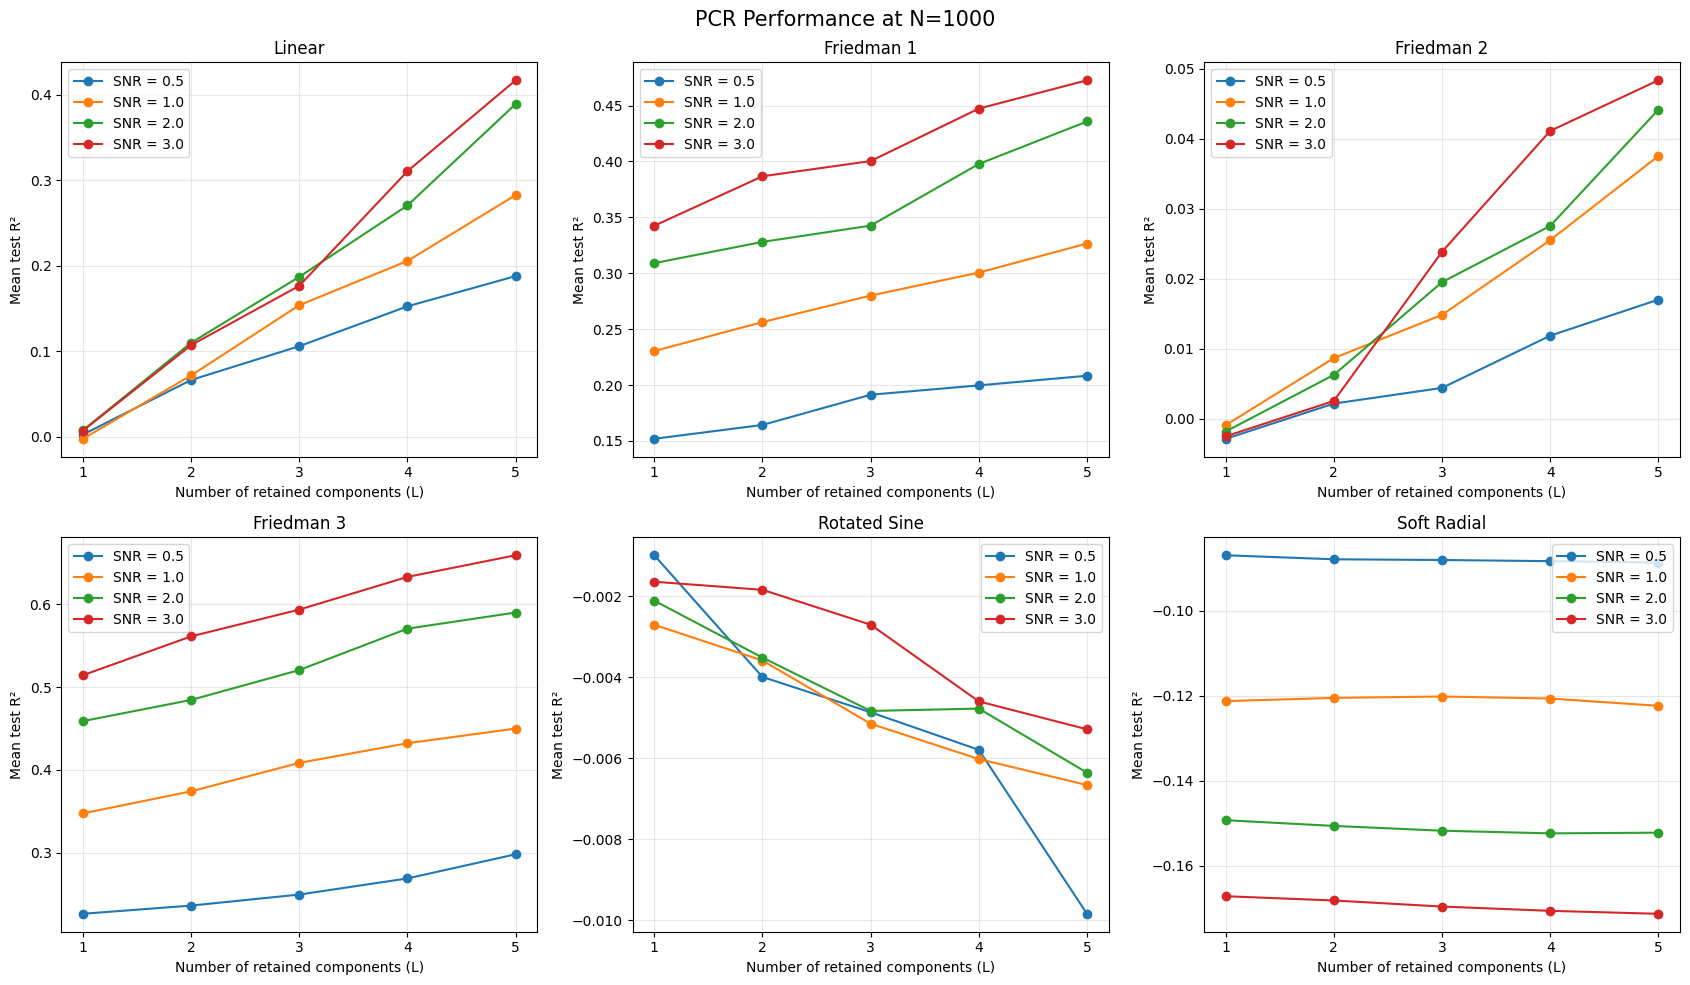

In [20]:
# Cell 20: PCR performance versus number of components
SELECTED_N = 1000
fig, axes = plt.subplots(2,3,figsize=(17,10))
axes = axes.flatten()

for ax, dgp_name in zip(axes, DGP_FUNCTIONS.keys()):
    subset = pcr_summary[(pcr_summary["DGP"] == dgp_name) & (pcr_summary["N_train"] == SELECTED_N)]
    for snr in SNR_VALUES:
        curve = (subset[subset["SNR"] == snr].sort_values("L"))
        ax.plot(curve["L"],curve["Mean_PCR_R2"],marker="o",label=f"SNR = {snr}")
    ax.set_title(dgp_name)
    ax.set_xlabel("Number of retained components (L)")
    ax.set_ylabel("Mean test R²")
    ax.set_xticks(PCR_COMPONENTS)
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle(f"PCR Performance at N={SELECTED_N}",fontsize=15)
plt.tight_layout()
plt.show()

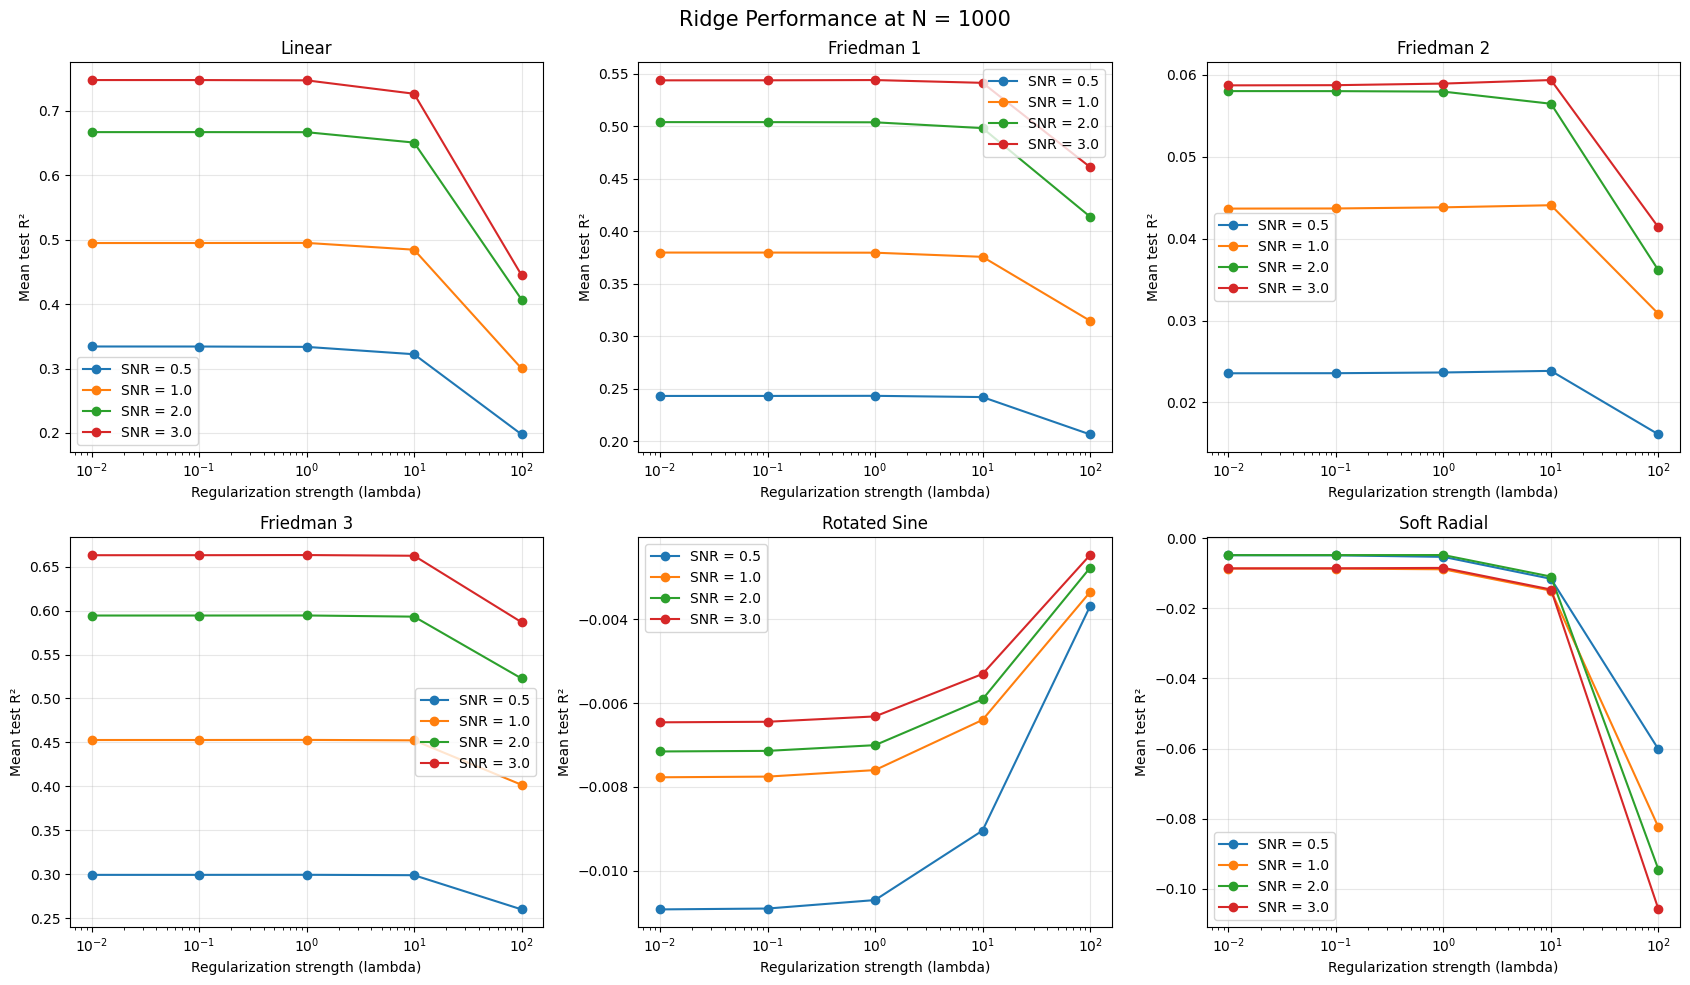

In [21]:
#Ridge performance versus regularization strength
fig, axes = plt.subplots(2,3,figsize=(17, 10))
axes = axes.flatten()

for ax, dgp_name in zip(axes, DGP_FUNCTIONS.keys()):
    subset = ridge_summary[(ridge_summary["DGP"] == dgp_name) & (ridge_summary["N_train"] == SELECTED_N)]
    for snr in SNR_VALUES:
        curve = (subset[subset["SNR"] == snr].sort_values("Lambda"))
        ax.plot(curve["Lambda"],curve["Mean_Ridge_R2"],marker="o",label=f"SNR = {snr}")
    ax.set_title(dgp_name)
    ax.set_xlabel("Regularization strength (lambda)")
    ax.set_ylabel("Mean test R²")
    ax.set_xscale("log")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle(f"Ridge Performance at N = {SELECTED_N}",fontsize=15)
plt.tight_layout()
plt.show()

the graph is showing the bias-variance tradeoff.

The graph shows how ridge regression's mean test \(R^2\) changes with regularization strength \(lambda) for six data-generating processes at a training sample size of \(N=1000\). Each panel represents a different DGP, and the colored lines correspond to SNR values of 0.5, 1, 2, and 3. For the Linear, Friedman 1, Friedman 2, and Friedman 3 DGPs, performance is generally stable at smaller regularization strengths but declines when \(\lambda\) reaches 100, indicating that excessive coefficient shrinkage can reduce predictive accuracy. For Rotated Sine and Soft Radial, test \(R^2\) remains negative across the plotted settings, suggesting that the linear ridge model struggles to capture these nonlinear relationships. Overall, the results demonstrate that the effect of regularization depends on the underlying DGP and SNR, and that stronger regularization does not necessarily improve performance. This experiment also verifies that conventional ridge regression and its regularized spectral-attention representation produce equivalent predictions across the full benchmark.

**Conclusion**

In this experiment, I extended the spectral-attention formulation to Principal Component Regression (PCR) and ridge regression. For PCR, I retained between one and five leading eigenvectors and compared conventional PCR predictions with their spectral-attention equivalents. For ridge regression, I evaluated five regularization strengths, ranging from 0.01 to 100. Across the full experimental grid, all 4,800 PCR evaluations and all 4,800 ridge evaluations produced equivalent predictions between the conventional and attention-based implementations, up to numerical precision. The results also showed that predictive performance depends on the number of retained components, regularization strength, signal-to-noise ratio, and underlying data-generating process. Strong regularization often reduced performance, while PCR performance generally improved when additional components captured useful signal. Overall, these experiments verified that spectral attention can reproduce both PCR and ridge regression predictions.

In [26]:

import zipfile
from pathlib import Path
from IPython.display import FileLink, display

BASE_DIR = Path("/kaggle/working")
EXPORT_DIR = BASE_DIR / "A11_Experiments_1_2_Completed"
ZIP_PATH = BASE_DIR / "Exp1_Exp2_All_Plots_Tables.zip"

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for exp_name in [
        "Experiment_1_OLS_as_Attention",
        "Experiment_2_Beyond_OLS"
    ]:
        exp_dir = EXPORT_DIR / exp_name
        for file in exp_dir.rglob("*"):
            if file.is_file() and file.suffix.lower() in [
                ".png", ".jpg", ".jpeg", ".pdf", ".svg",
                ".csv", ".html", ".md", ".xlsx"
            ]:
                z.write(file, file.relative_to(EXPORT_DIR))
display(FileLink(str(ZIP_PATH)))

/kaggle/working/Exp1_Exp2_All_Plots_Tables.zip